**NUR-E-JANNAT ANIKA**

CS 251/2: Data Analysis and Visualization

Fall 2025

In [49]:
%matplotlib notebook

In [9]:
%matplotlib ipympl

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import distance

import kmeans                                        

plt.style.use(['seaborn-v0_8-colorblind', 'seaborn-v0_8-darkgrid'])
plt.rcParams.update({'font.size': 20})

np.set_printoptions(suppress=True, precision=5)

# Automatically reload external modules
%load_ext autoreload
%autoreload 2

# Project 4 | Clustering

## Task 1: K-means clustering

In this task, you will implement the K-means clustering algorithm and test your code on simple test data.

### 1a. Import and plot `cluster2` data

In the cell below, use load in the `cluster2.csv` dataset (25 x,y values). Convert it (if necessary) to a ndarray with shape `(25, 2)`.

**NOTE:** You can either use your `Data` class to do this or NumPy (*see your recent labs if you need a refresher on how to load in a CSV file with only NumPy* ).

In [2]:
# YOUR CODE HERE   

filepath = ("data/cluster2.csv")
data = np.genfromtxt(filepath, delimiter=',', skip_header = 1)                                                             

print("Data shape:", data.shape)
print(data[:5])                                          
  

Data shape: (25, 2)
[[-1.2767  4.1072]
 [ 0.4342  3.493 ]
 [-0.5785  3.586 ]
 [-2.0465  3.9456]
 [-0.299   3.0866]]


Create a scatter plot below to see what the data look like.

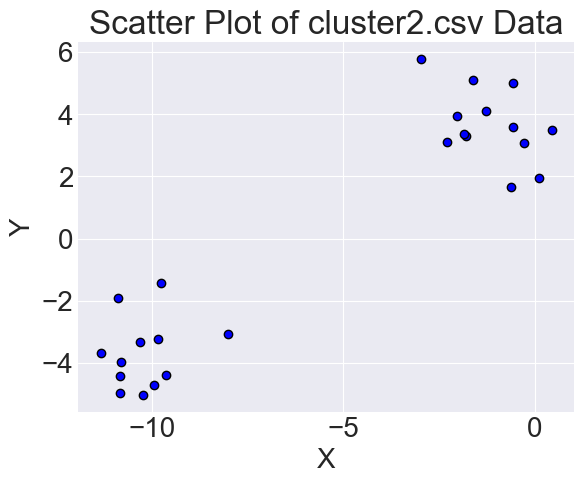

In [3]:
# YOUR CODE HERE                                        
plt.scatter(data[:, 0], data[:, 1], color='blue', edgecolor='k')
plt.title("Scatter Plot of cluster2.csv Data")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()


### 1b. Implement and test core K-means methods

In this task, you will implement the methods needed to cluster a dataset using K-means. The goal of this subtask is to create a scatter plot with each data sample color-coded based on the cluster it belongs to. You will be testing on the `cluster2` data.

In `kmeans.py` implement the following methods, using the following test code to help you out along the way:
- `set_data`: Update the data stored by the k-means clustering object.
- `get_data`: Return a copy of the data.
- `dist_pt_to_pt`: Compute the Euclidean distance from one data sample to one other. See below for formula.
- `dist_pt_to_centroids`: Compute the distance from one data sample to all the cluster centroids.
- `initialize`: Initialize K-means by setting the initial centroids
- `update_labels`: Assign each data sample to the nearest centroid
- `update_centroids`: Calculate each cluster's centroid, given the data samples that are assigned to it.
- `inertia`: Calculate the mean squared distance between each data sample and its (nearest) centroid. This is a 'quality of clustering' performance metric for analysis
- `cluster`: Run K-means to cluster the data. This is the actual method you call to do the clustering (above methods are helper methods).
- `plot_clusters`: Creates a scatter plot of the data (2D only) with data assigned to each cluster sharing the same color.

**Formula for Euclidean distance:**
$$dist \left (\vec{p_0}, \vec{p_1} \right ) = \sqrt{\left (d_{0} - e_{0} \right )^2 + \left (d_{1} - e_{1} \right )^2  + \ldots}$$

for data samples $\vec{p_0} = \left (d_{0}, d_{1}, \ldots \right )$ and $\vec{p_1} = \left (e_{0}, e_{1}, \ldots \right )$

#### Test constructor

In [4]:
import kmeans

In [21]:
cluster = kmeans.KMeans(k=3)
cluster.set_data(data)

print(f'Data isnt none? {np.all(cluster.data is not None)}')
print(f'Data num samples isnt None? {np.all(cluster.num_samps is not None)}')
print(f'Data num samples is {cluster.num_samps} and should be 25.')
print(f'Data num features isnt None? {np.all(cluster.num_features is not None)}')
print(f'Data num features is {cluster.num_features} and should be 2.')                    
                      
  

Data isnt none? True
Data num samples isnt None? True
Data num samples is 25 and should be 25.
Data num features isnt None? True
Data num features is 2 and should be 2.


#### Test `get_data`

In [22]:
super_simple_cpy = cluster.get_data()
super_simple_cpy[0,:] = -99
if np.all(cluster.data[0,:] == -99):
    print('You didnt return a copy of the data! Re-import the super_simple data and try again...')
else:
    print('All good!')

All good!


#### Test `dist_pt_to_pt`

In [23]:
a = np.array([1, 2, 3, 4])
b = 4*a
print(f'Your pt-to-pt distance is {cluster.dist_pt_to_pt(a, b):.4f}')
print('Correct pt-to-pt distance is 16.4317')

Your pt-to-pt distance is 16.4317
Correct pt-to-pt distance is 16.4317


#### Test `dist_pt_to_centroids`

In [24]:
test_pt = np.array([[1, 2]])                                                            
test_centroids = np.array([[9, 9], [11, 11], [0, 0]])
print(f'Your pt-to-centroids distance is {cluster.dist_pt_to_centroids(test_pt.flatten(), test_centroids)}')
print(f'Correct pt-to-centroids distance is {distance.cdist(test_pt, test_centroids)[0]}')

Your pt-to-centroids distance is [10.63015 13.45362  2.23607]
Correct pt-to-centroids distance is [10.63015 13.45362  2.23607]


tion was the direct cause of the following exception:

Traceback (most recent call last):
  File "/Users/anika/myenv/lib/python3.12/site-packages/tornado/ioloop.py", line 937, in _run
    val = self.callback()
          ^^^^^^^^^^^^^^^
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/backend_bases.py", line 1179, in _on_timer
    ret = func(*args, **kwargs)
          ^^^^^^^^^^^^^^^^^^^^^
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1417, in _step
    self._init_draw()
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1733, in _init_draw
    self._draw_frame(frame_data)
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1752, in _draw_frame
    self._drawn_artists = self._func(framedata, *self._args)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/yj/7196s0912vb7pv1x94mtgd_w0000gn/T/ipykernel_57222/141757543.py", line 17,

#### Test `initialize`

In [25]:
test_k = 3                                        
init_centroids = cluster.initialize(test_k)
print(f'Initial cluster centroids shape is:\n{init_centroids.shape} and should be (3, 2)')
print(f'Initial inertia is:\n{cluster.inertia} and should be inf')

Initial cluster centroids shape is:
(3, 2) and should be (3, 2)
Initial inertia is:
<bound method KMeans.inertia of <kmeans.KMeans object at 0x15c086ae0>> and should be inf


#### Test `update_labels`

In [26]:
# Consistently set initial centroids for test                                                            
init_centroids = np.array([[ 0.338, 4.4672], [-1.8401, 3.1123], [1.7931, 0.5427]])

new_labels = cluster.update_labels(init_centroids)
print(f'After the first update data label step, 1st 10 of your cluster assignments are:\n{new_labels[:10]}')
print('Your 1st 10 cluster assignments should be:\n[1 0 0 1 0 1 1 1 1 1]')

After the first update data label step, 1st 10 of your cluster assignments are:
[1 0 0 1 0 1 1 1 1 1]
Your 1st 10 cluster assignments should be:
[1 0 0 1 0 1 1 1 1 1]


#### Test `update_centroids` (1/2)

In [27]:
new_centroids, diff_from_prev_centroids = cluster.update_centroids(test_k, new_labels, init_centroids)                                        

print(f'After the first centroid update, your cluster assignments are:\n{new_centroids}')
print(f'Your difference from previous centroids:\n{diff_from_prev_centroids}')
print('\nYou should see:')
print('''After the first centroid update, your cluster assignments are:
[[-0.25525  3.79378]
 [-6.84678 -0.68793]
 [ 0.095    1.9343 ]]
Your difference from previous centroids:
[[-0.59325 -0.67342]
 [-5.00668 -3.80023]
 [-1.6981   1.3916 ]]
''')

After the first centroid update, your cluster assignments are:
[[-0.25525  3.79378]
 [-6.84678 -0.68793]
 [ 0.095    1.9343 ]]
Your difference from previous centroids:
[[-0.59325 -0.67342]
 [-5.00668 -3.80023]
 [-1.6981   1.3916 ]]

You should see:
After the first centroid update, your cluster assignments are:
[[-0.25525  3.79378]
 [-6.84678 -0.68793]
 [ 0.095    1.9343 ]]
Your difference from previous centroids:
[[-0.59325 -0.67342]
 [-5.00668 -3.80023]
 [-1.6981   1.3916 ]]



#### Test `update_centroids` (2/2)

Test special case when no sample gets assigned to one of the clusters.

In [28]:
np.random.seed(0)                                                            

print('Test 2: There are 5 clusters, but no samples assigned to 3rd and last cluster.')
print('There should be no Runtime warnings thrown and the centroid arrays should not have any nan values.')
print(100*'-')
test_k_2 = 5
new_labels_2 = new_labels.copy()
new_labels_2[new_labels_2 == 2] = 3
init_centroids_2 = np.vstack([init_centroids, np.random.random(size = (2, 2))])
new_centroids_2, diff_from_prev_centroids_2 = cluster.update_centroids(test_k_2, new_labels_2, init_centroids_2)
print(f'After the first centroid update, your cluster assignments are:\n{new_centroids_2}')
print(f'Your difference from previous centroids:\n{diff_from_prev_centroids_2}')

Test 2: There are 5 clusters, but no samples assigned to 3rd and last cluster.
There should be no Runtime warnings thrown and the centroid arrays should not have any nan values.
----------------------------------------------------------------------------------------------------
After the first centroid update, your cluster assignments are:
[[-0.25525  3.79378]
 [-6.84678 -0.68793]
 [ 1.7931   0.5427 ]
 [ 0.095    1.9343 ]
 [ 0.60276  0.54488]]
Your difference from previous centroids:
[[-0.59325 -0.67342]
 [-5.00668 -3.80023]
 [ 0.       0.     ]
 [-0.45381  1.21911]
 [ 0.       0.     ]]


You should see: 
    
    After the first centroid update, your cluster assignments are:
    [[ -0.25525   3.79378]
    [ -6.84678  -0.68793]
    [some_float  some_float ]
    [  0.095     1.9343 ]
    [some_float  some_float ]]
    Your difference from previous centroids:
    [[ -0.59325  -0.67342]
    [ -5.00668  -3.80023]
    [some_float  some_float ]
    [ -0.45381   1.21911]
    [some_float  some_float]]

**NOTE:** Each `some_float` above should be a different random float value and not `nan` or all `0`s.

#### Test `inertia`

In [29]:
cluster.centroids = new_centroids                                                                                
cluster.data_centroid_labels = new_labels
print(f'After the first test k-means update, your inertia is:\n{cluster.compute_inertia():.4f}\nIt should be\n25.8417')

After the first test k-means update, your inertia is:
25.8417
It should be
25.8417


#### Test `plot_clusters` and `cluster`

In the cell below:

1. Run K-means on the `cluster2` dataset, picking $k$ that makes sense.
2. Run `plot_clusters` to generate a scatter plot showing the cluster assignments of the data in different colors. Nearby samples in your scatter plot should have the same color most of the times that you run your code (*this may not be true **every** time you run your code to generate the plot and that is expected! You are aiming for most of the time.*). Your clustering is working as expected if every sample in each visual cluster has the same color.

*Reminder: you should be using the custom qualitative RGB color palette.*

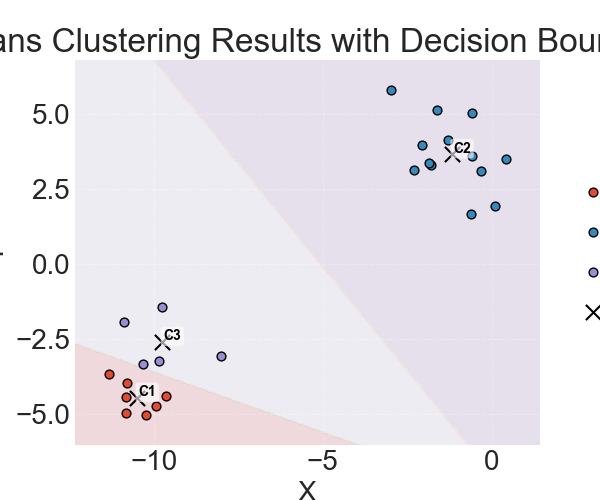

In [30]:
# YOUR CODE HERE                                   
filepath = "data/cluster2.csv"                                        
  
  
data2 = np.genfromtxt(filepath, delimiter = ",", skip_header = 1)                                        
  
  
cluster = kmeans.KMeans(k = 3, max_iters = 100)
cluster.set_data(data2)
np.random.seed(0)
cluster.cluster()
cluster.plot_clusters()

### 1c. Determining the number of clusters $k$

In this task, you will explore how to determine the number of clusters in a dataset.

1. Implement `elbow_plot` in `kmeans.py`.
2. Create an elbow plot below for the `cluster2` dataset. It should look like the below image.

**NOTE:** Make sure to include a meaningful x label, y label, and x tick marks.

Your plot should show a clear plateau, starting at the number of visual clusters.

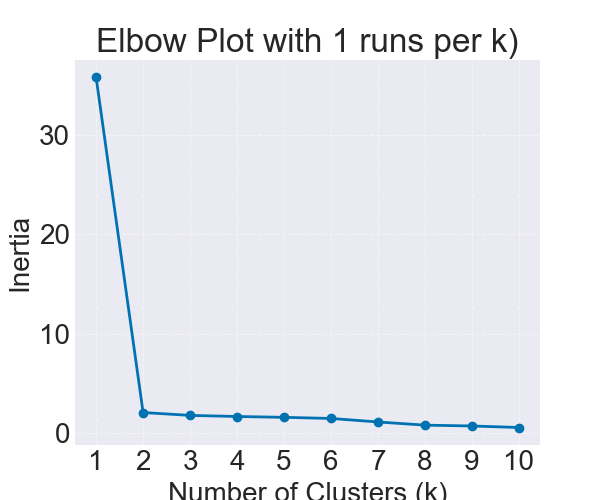

In [31]:
# YOUR CODE HERE
cluster.elbow_plot(max_k = 10)

### 1d. Clustering the `cluster5` dataset

Load in the `cluster5` dataset then in the cell below:
1. create a scatter plot showing the 2D dataset (without any clustering).
2. run K-means to cluster the dataset with a reasonable number of clusters (based on what you observe in the scatter plot).
3. create a scatter plot showing the clustered data.

tion was the direct cause of the following exception:

Traceback (most recent call last):
  File "/Users/anika/myenv/lib/python3.12/site-packages/tornado/ioloop.py", line 937, in _run
    val = self.callback()
          ^^^^^^^^^^^^^^^
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/backend_bases.py", line 1179, in _on_timer
    ret = func(*args, **kwargs)
          ^^^^^^^^^^^^^^^^^^^^^
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1417, in _step
    self._init_draw()
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1733, in _init_draw
    self._draw_frame(frame_data)
  File "/Users/anika/myenv/lib/python3.12/site-packages/matplotlib/animation.py", line 1752, in _draw_frame
    self._drawn_artists = self._func(framedata, *self._args)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/yj/7196s0912vb7pv1x94mtgd_w0000gn/T/ipykernel_57222/141757543.py", line 17,

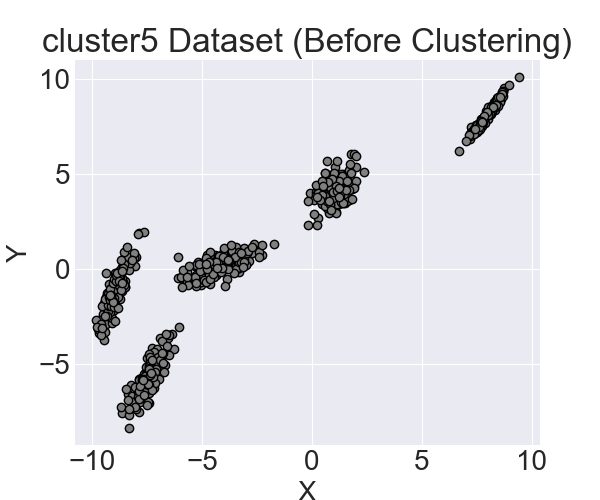

In [32]:
filepath = "data/cluster5.csv"
data3 = np.genfromtxt(filepath, delimiter = ",", skip_header = 1)

plt.figure(figsize = (6,5))
plt.scatter(data3[:,0], data3[:,1], color = 'gray', edgecolor = 'k')
plt.title("cluster5 Dataset (Before Clustering)")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()

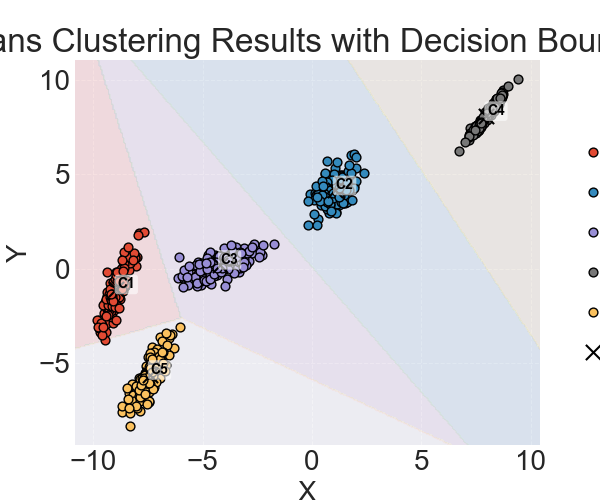

In [33]:
cluster = kmeans.KMeans(k = 5, max_iters = 100)
cluster.set_data(data3)
np.random.seed(0)
cluster.cluster()
cluster.plot_clusters()

### 1e. Clustering results over repeated runs of K-means

Copy-and-paste your above code to the cell below then modify the code to run K-means 5 times. Keep the random seed to ensure that you get consistent clustering results if you execute the cell multiple times. The below cell should output 5 scatter plots, each showing the clustering results from a different run of K-means.

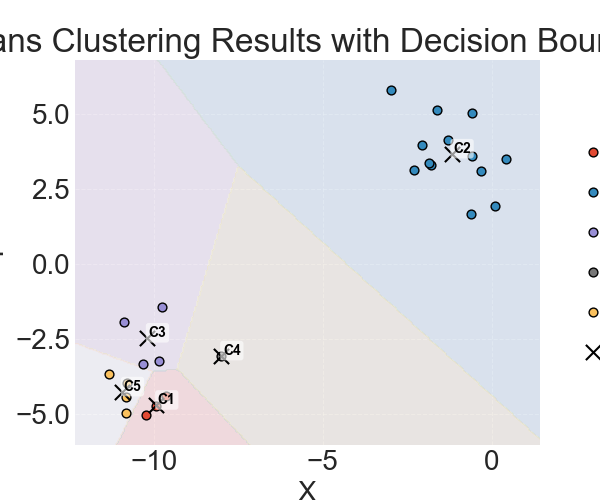

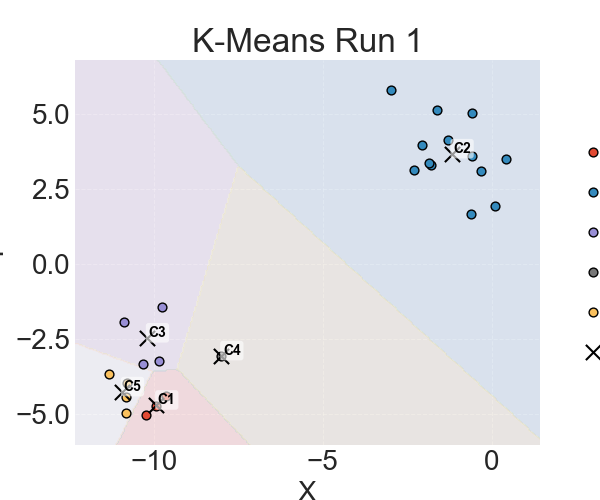

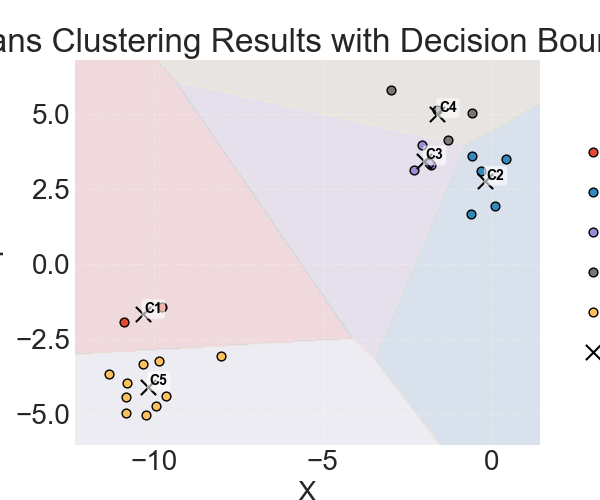

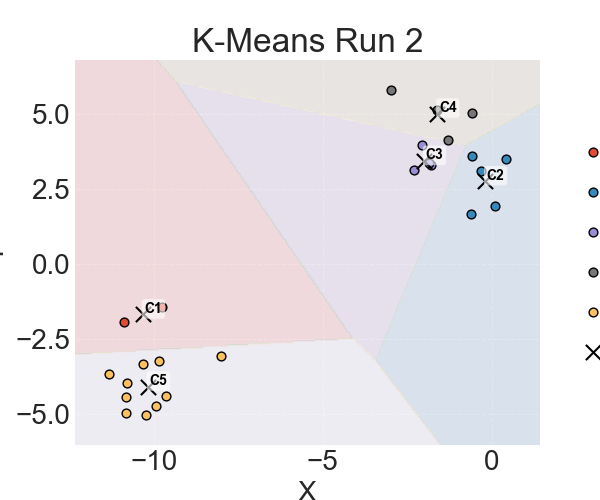

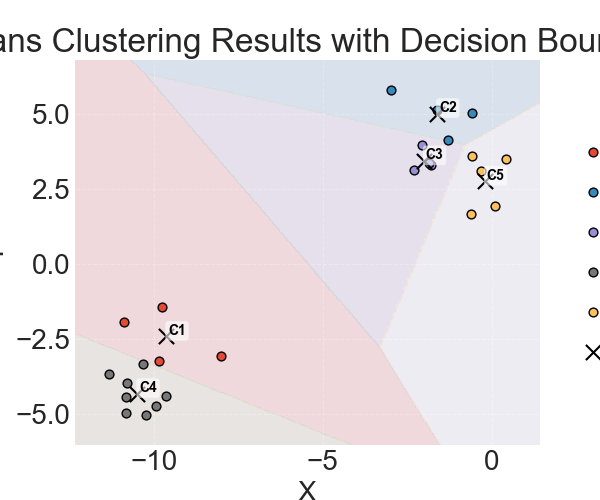

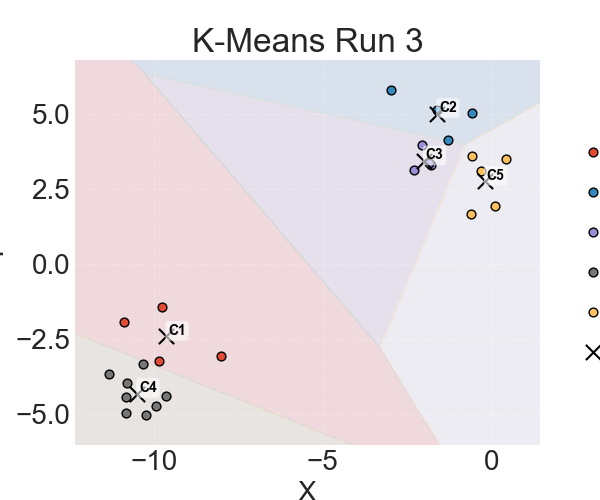

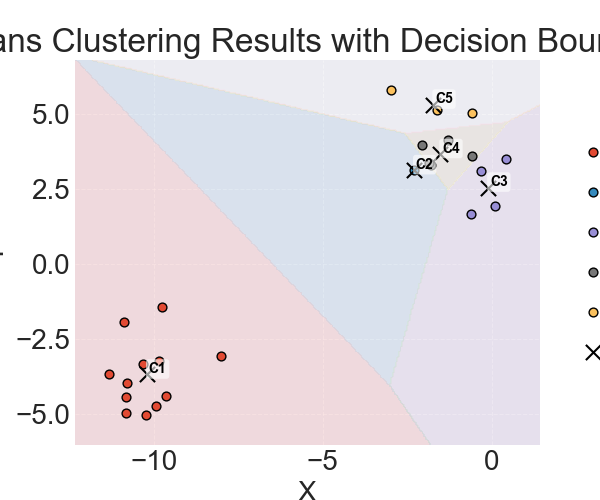

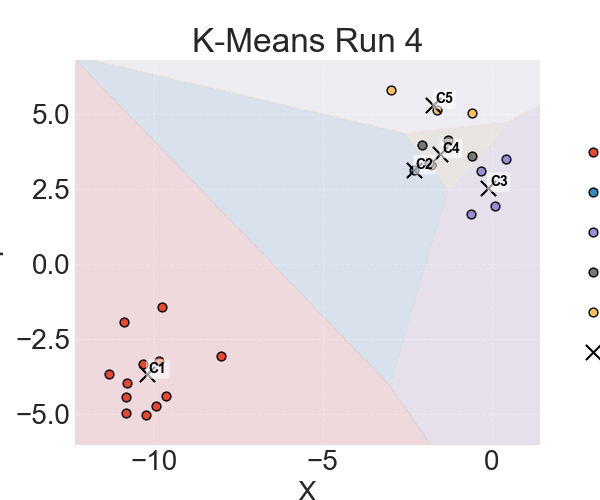

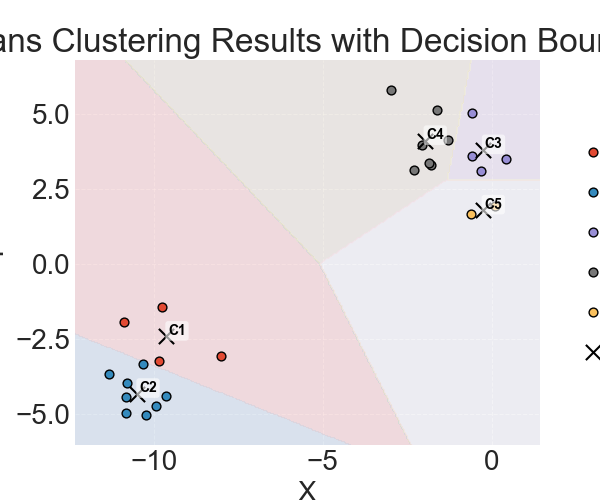

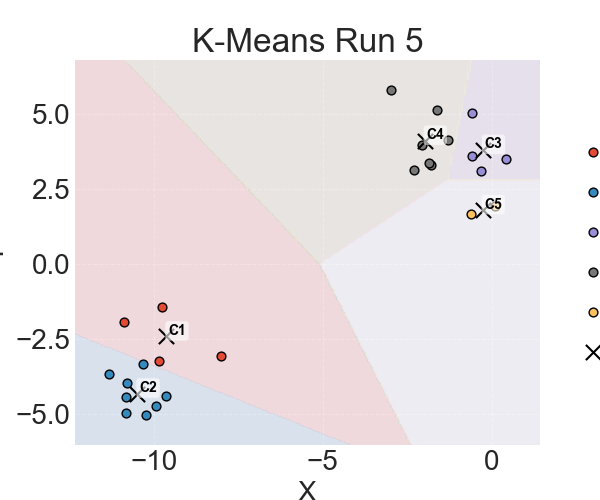

In [34]:
for run in range(5):
    np.random.seed(run) 
    cluster = kmeans.KMeans(k = 5, max_iters = 100)
    cluster.set_data(data2)
    cluster.cluster()
    cluster.plot_clusters()
    plt.title(f"K-Means Run {run + 1}")                    
    plt.show()                    
                

### 1f. Questions

**Question 1:**  What do you observe about how the cluster assignments match up with the clusters that you see visually? **Why does this happen?**

**Answer 1:** 
Across the five runs, the visual clusters in the scatter plots almost look the same:                                                            
- The same groups of nearby points are assigned to the same colors (cluster IDs).

- The centroids end up in quite similar locations each time.

A possible reason is K-Means clustering always starts with random initial centroids and final result depends on this initialization. 
Each time we run it, the algorithm firstly randomly picks starting positions for the centroids and it then iteratively re-assigns points and re-computes centroids until convergence. Depending on where it starts, it may label clusters slightly differently (as seen in the plots abover where the numeric label order changes). But dataset seems to have have well-separated clusters (as seen in the original without clustering scatter plot), which is why the K-Means converges to very similar final clusters every time, regardless of initialization.

YOUR ANSWER HERE

### 1g. Elbow plots over repeated runs of K-means
Copy-and-paste your above code to the cell below then modify the code to create 5 elbow plots. Each elbow plot should plot 10 values, the inertia obtained when clustering the dataset with `k` = 1, 2, ..., 10. Keep the random seed to ensure that you get consistent clustering results if you execute the cell multiple times.

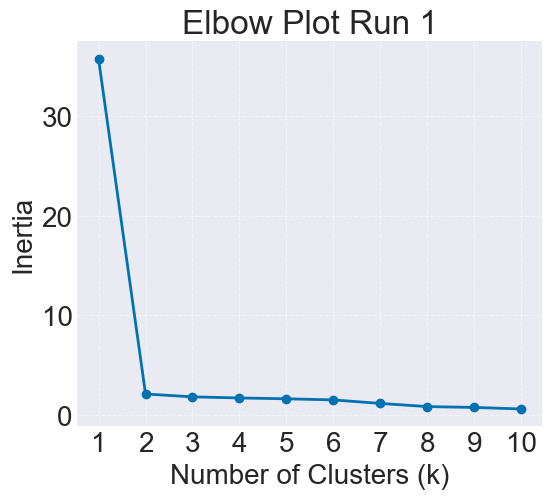

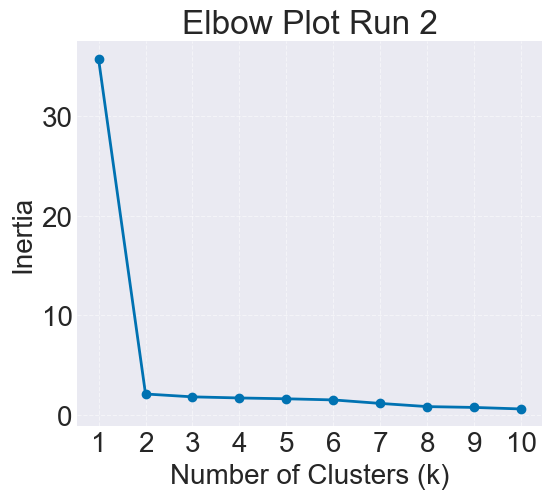

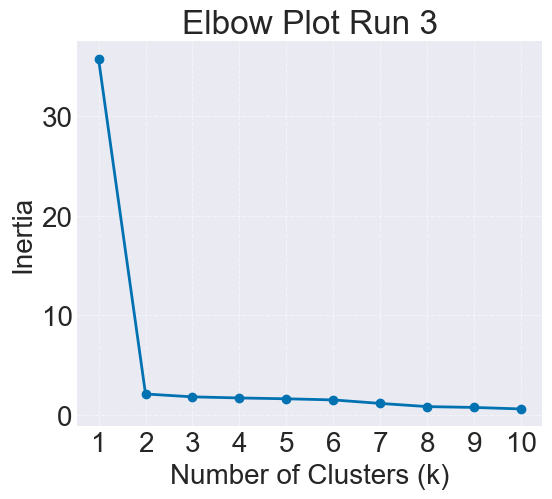

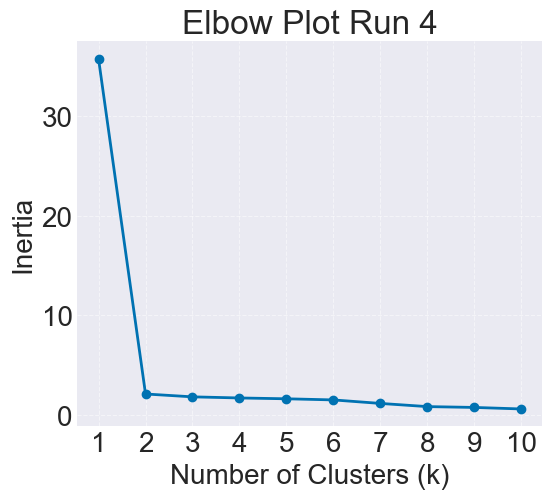

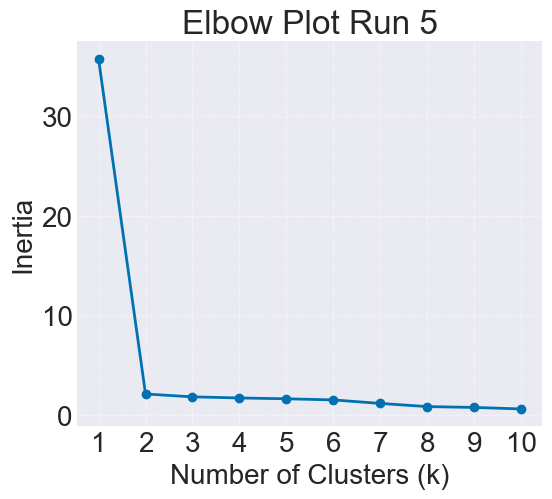

In [83]:
# YOUR CODE HERE                    
for run in range(5):
    np.random.seed(run)
    cluster = kmeans.KMeans(max_iters = 100)
    cluster.set_data(data2)
    cluster.elbow_plot(max_k = 10)
    plt.title(f"Elbow Plot Run {run + 1}")
    plt.show()                                                            
  

### 1h. Questions 

**Question 2:** If you had to only rely on the elbow plots to determine the number of clusters (without looking at the scatter plots), how many clusters do you estimate the dataset has?

**Answer 2:** 

YOUR ANSWER HERE

From the elbow plots, there is a clear drop in inertia between k = 1 and k = 2, and ater that there is only small decreases. This forms an “elbow” around k = 2 or k = 3, where adding more clusters doesn’t significantly reduce the inertia. Therefore, based solely on the elbow plots, I would estimate that the dataset has approximately 2 to 3 clusters. 

**Question 3:** How predictive is the elbow plot of the number of visual clusters in the dataset?

**Answer 3:**

YOUR ANSWER HERE

The elbow plot is highly predictive in this case because the dataset has well-separated visual clusters, and the “elbow” clearly appears where the true number of clusters is. This means the inertia metric correctly reflects the structure of the data.

However, in more complex or overlapping datasets, the elbow plot can be less reliable, since the decrease in inertia may be gradual or unclear. But for this dataset, it does a good job — it correctly suggests around 3 clusters, which matches the number of visible clusters in the scatter plots.

### 1i. Run K-means multiple times, save the best clustering

To address what you observed above, we can run K-means multiple times and take the best results to determine the final clustering. Implement `cluster_batch` to run K-means multiple times with a chosen $k$ value.

In the cell below, run `cluster_batch` with 10 iterations for the `k` value you identified in Task 1e above. Make a new scatterplot of the cluster assignments.

Best inertia after 10 runs: 0.8532


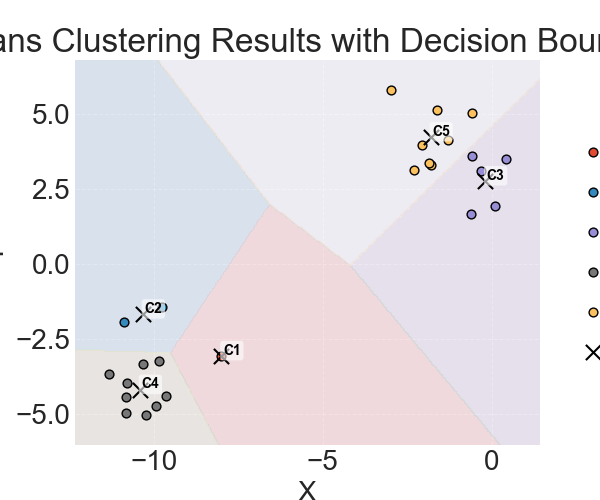

In [35]:
cluster = kmeans.KMeans(max_iters = 100)
cluster.set_data(data2)

best_labels, best_centroids, best_inertia = cluster.cluster_batch(k = 5, n_iter = 10)
print(f"Best inertia after 10 runs: {best_inertia:.4f}")

cluster.plot_clusters()

### 1j. Questions

**Question 4:** Based on the clustered results above, in way ways (if any) did the clustering improve compared with what you found in Task 1e? **Why?**

**Answer 4:**

YOUR ANSWER HERE

Compared to Task 1e, the clustering results in Task 1i are slightly more stable and optimized. From Task 1e, the visual results were mostly consistent, but there were minor differences in cluster label assignments or centroid locations between runs. Here in 1j, The cluster centroids are positioned more precisely at the centers of their respective point groups, and the cluster assignments are more consistent. This improvement occurs because cluster_batch runs K-Means multiple times with different random initializations and keeps the result with the lowest inertia. By doing this, it avoids poor local minima and ensures that the final clustering is the best among all trials.

### 1i. Update elbow plot for the `cluster5` dataset

Now that you have experimented with `cluster` and `cluster_batch`, update your `elbow_plot` method to use `cluster_batch` instead of `cluster`. To do this, add a keyword argument `n_iter` to `elbow_plot`. Give it a default value of 1. (*And don't forget to update the docstring to include the new parameter!*)

In the cell below, test out your updated `elbow_plot` method using the same max $k$ value and number of iterations (for each $k$ value) as you used above. Create an elbow plot showing the inertia with different $k$ values.

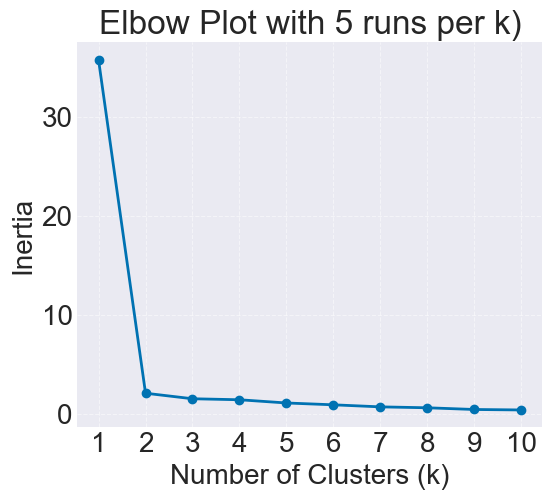

In [68]:
# YOUR CODE HERE                                        
cluster.elbow_plot(max_k = 10, n_iter = 5)

### 1j. Questions

**Question 5:** Run the above cell several times and examine the resulting elbow plot. How predictive and reliable is the updated elbow plot of the number of clusters in the dataset compared to the previous ones that you made?

**Answer 5:** 

YOUR ANSWER HERE

Original elbow_plot() ran K-Means once per k, so the result would depend on random starting points.

Updated elbow_plot() runs multiple times per k and keeps the best inertia. This means for each value of k, the plotted inertia is the lowest possible value found across runs. Therefore, the elbow curve becomes smoother and less noisy, giving a more trustworthy indication of the optimal k.

## Extension

I wanted to make K-Means feel more intuitive and visual so that you can literally see the algorithm learning and making better clusters. 


In [12]:
import kmeans_extension
from matplotlib.animation import FuncAnimation

In [27]:
                    
df = pd.read_csv("data/Mall_Customers.csv")

data = df[['Age', 'Spending Score (1-100)']].values

# data = np.genfromtxt("data/cluster2.csv", delimiter=",", skip_header=1)
cluster = kmeans_extension.KMeans(k=4, max_iters=10)
cluster.set_data(data)

labels_history, centroids_history = cluster.run_with_history()

✅ Converged at iteration 4


**run_with_history()**  

- It records the centroids and labels at every iteration — so I can replay them later frame by frame and see them together in a video or animation. Initially, my animation didn’t run in order — I’d see Iteration 7 before Iteration 2, or sometimes it’d jump backward.
- animation frames don’t necessarily match the logical order of iteration unless you store the state explicitly.
I had to make run_with_history() return ordered lists of labels_history and centroids_history. 


**Update():** 

- It’s called once per frame by FuncAnimation, and it completely redraws the scene for that iteration.                    
  
- Inside update(), I clear the axes, take the right labels and centroids from run_with_history(), recompute the color regions, scatter the data, draw the centroids, and label them. 


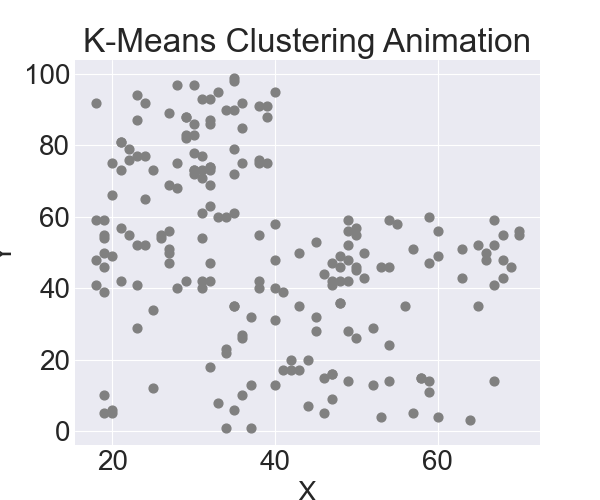

In [31]:
fig, ax = plt.subplots(figsize=(6,5))                                                                                                    

# Initialize scatter plots
scatter = ax.scatter(data[:,0], data[:,1], c='gray', s=40)
centroid_plot = ax.scatter([], [], c='black', marker='x', s=100)

ax.set_title("K-Means Clustering Animation")
ax.set_xlabel("X")
ax.set_ylabel("Y")

def update(frame):
    labels = labels_history[frame]
    centroids = centroids_history[frame]

    scatter.set_color([plt.cm.tab10(int(l % 10)) for l in labels])
    centroid_plot.set_offsets(centroids)
    ax.set_title(f"K-Means Iteration {frame+1}")
    return scatter, centroid_plot

anim = FuncAnimation(fig, update, frames=len(labels_history), interval=1000, blit=False)
plt.show()



I wanted to add the background regions: these are basically Voronoi-like regions, which is just computing the distance from each grid point to all centroids and shading the region with the nearest centroid’s color.

For this, I had to learn the cocept of creating meshgrid. 

In [17]:
# Defining grid limits                    
  
x_min, x_max = data[:, 0].min() - 1, data[:, 0].max() + 1
y_min, y_max = data[:, 1].min() - 1, data[:, 1].max() + 1

#Creating meshgrid for background shading 
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

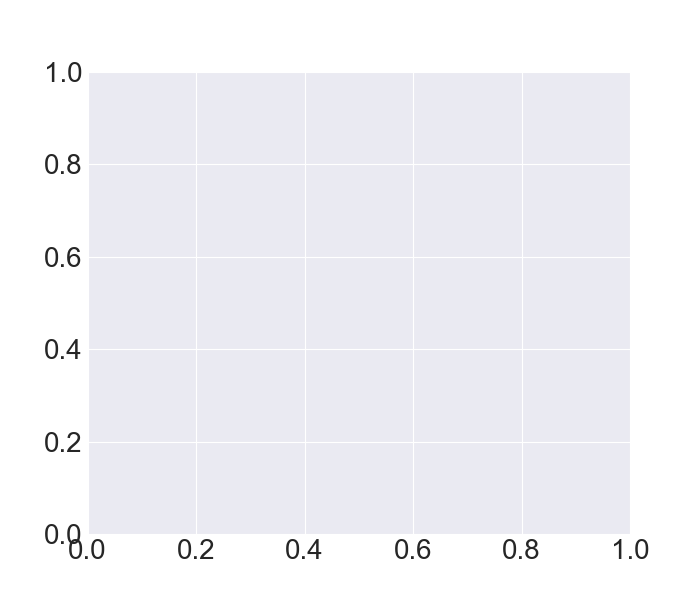

In [32]:
fig, ax = plt.subplots(figsize=(7, 6))

def update(frame):
    ax.cla()
    labels = labels_history[frame]
    centroids = centroids_history[frame]

    # Computing boundaries
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    distances = np.linalg.norm(grid_points[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
    Z = np.argmin(distances, axis=1).reshape(xx.shape)

    # Background regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Pastel1")

    # Data points
    ax.scatter(data[:, 0], data[:, 1], c=labels, cmap="Set1", s=50, edgecolor="k")

    # Centroids
    ax.scatter(centroids[:, 0], centroids[:, 1], c="red", s=200, marker="o", edgecolor="k", alpha=0.9) 

    ax.set_title(f"K-Means Iteration {frame + 1}", fontsize=14, pad=10)
    ax.set_xlabel("Age")
    ax.set_ylabel("Spending Score (1–100)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(False)
    return ax,

# animation setup    
anim = FuncAnimation(
    fig,
    update,
    frames=len(labels_history),
    interval=2000, 
    blit=False,
    repeat = False
)

plt.show()                    
                                                                                  
  
  
  

I just wanted to make more visual improvements, for example the centroid color and cluster points colors being the same make it difficult to understand and track the centroid points. 

- I learned how Matplotlib colormaps work. I created two separate color palettes: one for cluster points and one for centroids.                    
  
- I also added boxes around the labels using bbox from matplotlib. 


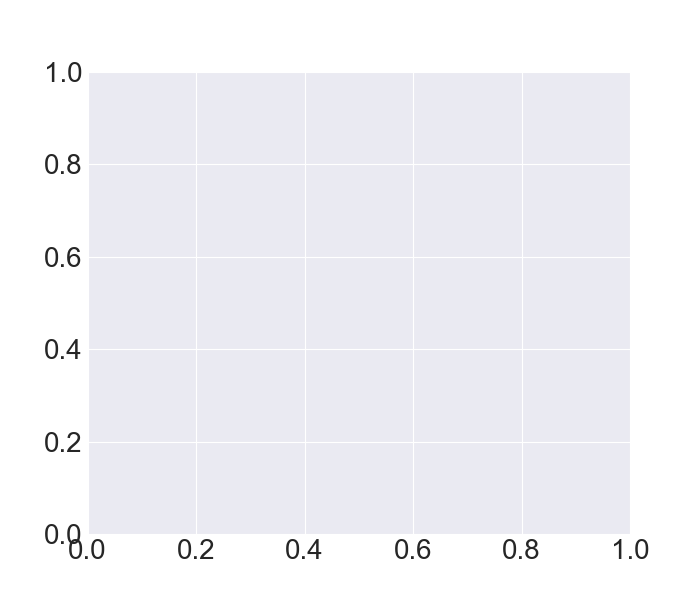

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))

cluster_colors = ['#E24A33', '#348ABD', '#988ED5', '#777777', '#FBC15E']
centroid_colors = ['#FF0000', '#00CC44', '#6600CC', '#FF9900', '#00CCCC']

def update(frame):
    ax.cla()
    labels = labels_history[frame]
    centroids = centroids_history[frame]

    # Computing boundaries
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    distances = np.linalg.norm(grid_points[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
    Z = np.argmin(distances, axis=1).reshape(xx.shape)

    # Background regions                    
    ax.contourf(xx, yy, Z, alpha=0.25, levels=np.arange(cluster.k + 1) - 0.5,
                colors=colors[:cluster.k])

    # Data points
    for i in range(cluster.k):
        cluster_points = data[labels == i]
        ax.scatter(cluster_points[:, 0], cluster_points[:, 1],
                   s=50, color=colors[i], edgecolor='k', label=f"Cluster {i + 1}")

    # Centroids 
    ax.scatter(centroids[:, 0], centroids[:, 1],
               c=centroid_colors[:cluster.k], s=200, marker='o',
               edgecolor='black', linewidth=1.5, alpha=0.9)

    # Centroid labels
    for i, (x, y) in enumerate(centroids):
        ax.text(x + 0.5, y + 1.0, f"C{i + 1}",
                fontsize=9, weight='bold', color='black',
                bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.2'))

 
    ax.set_title(f"K-Means Iteration {frame + 1}", fontsize=14, pad=10)
    ax.set_xlabel("Age")
    ax.set_ylabel("Spending Score (1–100)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(False)

   
    if frame == 0:
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)

    return ax,

# Animation setup
anim = FuncAnimation(
    fig,
    update,
    frames=len(labels_history),
    interval=2000,  
    blit=False,
    repeat=False
)

plt.show()

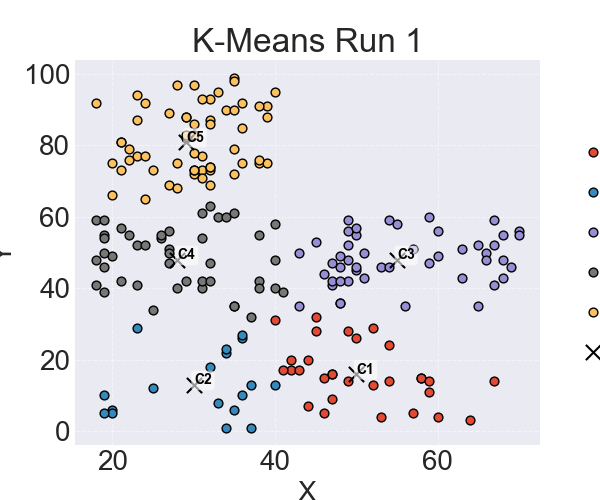

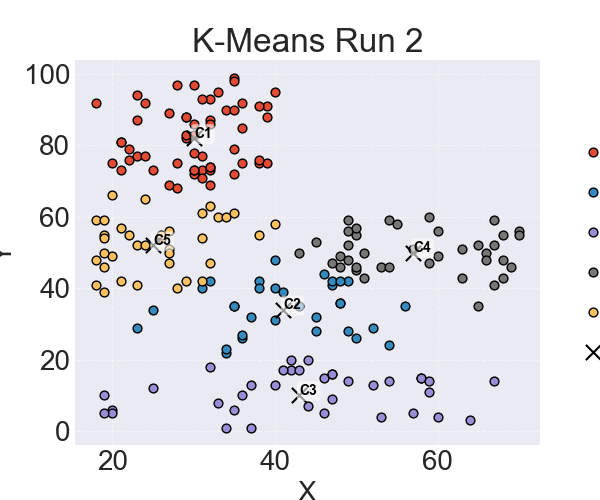

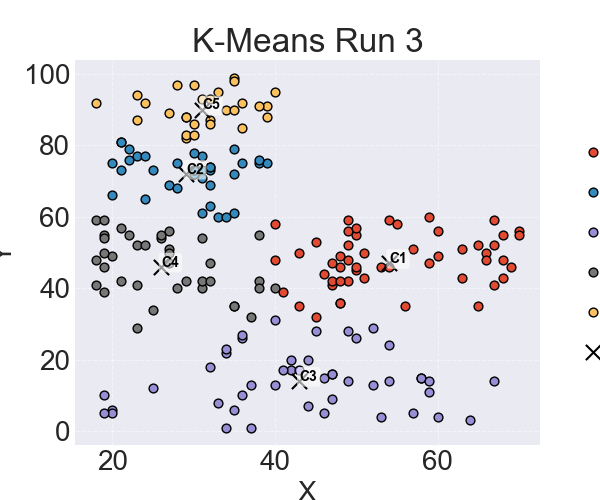

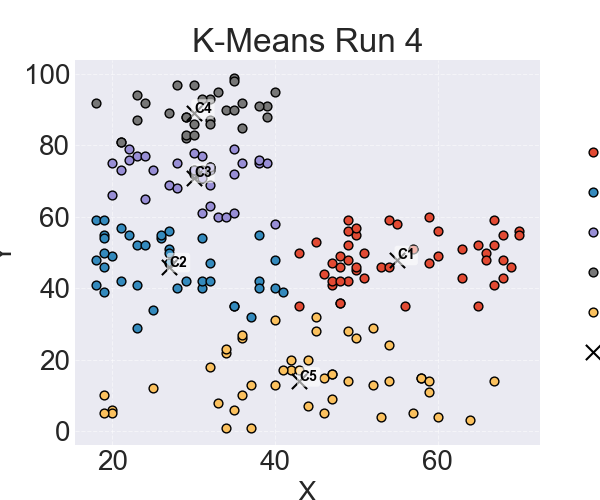

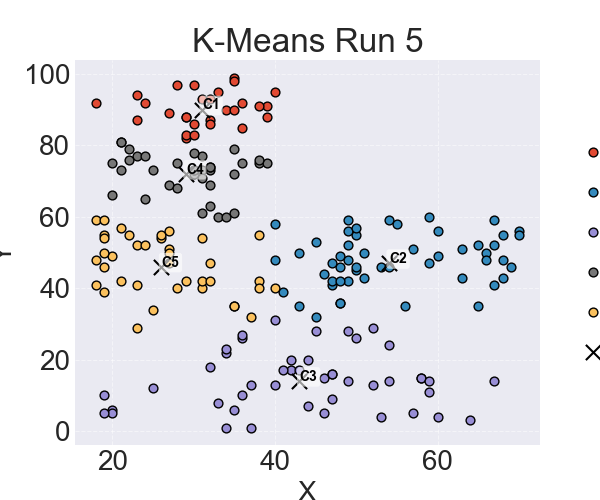

In [26]:
# When I don't use animation

for run in range(5):
    np.random.seed(run) 
    cluster = kmeans_extension.KMeans(k = 5, max_iters = 100)
    cluster.set_data(data)
    cluster.cluster()
    cluster.plot_clusters()
    plt.title(f"K-Means Run {run + 1}")                    
    plt.show()

**The animation shows the process of convergence — you can literally watch the centroids move after each iteration and the clusters reorganize around them.**

In [20]:
# import sys                    
  
# print(sys.argv)

['/Users/anika/myenv/lib/python3.12/site-packages/ipykernel_launcher.py', '-f', '/Users/anika/Library/Jupyter/runtime/kernel-29e9ce39-0de1-45ed-ac5f-a390c2ca8e8f.json']
